Assignment 3: Predicting Next-Day Agitation in People Living with Dementia

**Classification task:** Using the data collected on a given day (movement in the home, sleep, vital signs, past alerts), predict whether the participant will have a medically confirmed **agitation** alert on the **next day**. Each row is one participant on one day, and the target is 1 if agitation is confirmed the next day and 0 otherwise.

Agitation was chosen because it is the alert type with the most events (115 participant-days across 27 participants), and an early warning would be useful for caregivers. The methods from class (decision trees, kNN, naive Bayes, logistic regression, SVM, bagging, random forest, boosting), and a neural network are compared.

In [16]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings('ignore')   # hides a harmless deprecation warning from SVC(probability=True)

In [17]:
# Use a path relative to the notebook location and search for the dataset in common locations.
base_dir = os.path.dirname(os.path.abspath('Assignment_3_Classification.ipynb'))
required_files = {'Activity.csv', 'Sleep.csv', 'Physiology.csv', 'Labels.csv', 'Demographics.csv'}

candidate_dirs = [
    os.path.join(base_dir, 'Dataset'),
    os.path.join(base_dir, 'dataset'),
    os.path.join(base_dir, 'TIHM-Dataset', 'analysisFiles', 'Dataset'),
    os.path.join(base_dir, 'TIHM-Dataset', 'Dataset'),
    os.path.join(base_dir, '..', 'Dataset'),
    os.path.join(base_dir, '..', 'dataset'),
]

for root, dirs, files in os.walk(base_dir):
    if required_files.issubset(set(files)):
        candidate_dirs.insert(0, root)
        break

for candidate in candidate_dirs:
    if os.path.isdir(candidate):
        data_dir = candidate
        break
else:
    raise FileNotFoundError(
        f"Could not locate the TIHM dataset directory under {base_dir}. "
        f"Expected files: {sorted(required_files)}"
    )

def read_dataset_csv(filename):
    path = os.path.join(data_dir, filename)
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")
    return pd.read_csv(path)

activity = read_dataset_csv('Activity.csv')
sleep = read_dataset_csv('Sleep.csv')
physiology = read_dataset_csv('Physiology.csv')
labels = read_dataset_csv('Labels.csv')
demographics = read_dataset_csv('Demographics.csv')


**Step 1: Build one table with one row per participant per day**

The tables from earlier assignments are on different time scales (activity is event-level, sleep is every minute, physiology is a few readings per day), so each one is summarized to a single value per participant per day and then joined together.

In [18]:
# convert all dates to datetime and keep a date-only column
for t in [activity, sleep, physiology, labels]:
    t['dt'] = pd.to_datetime(t['date'])
    t['day'] = t['dt'].dt.normalize()
activity['hour'] = activity['dt'].dt.hour

In [19]:
# activity: number of movements in each location per day
act = activity.pivot_table(index=['patient_id','day'], columns='location_name', values='hour', aggfunc='count', fill_value=0)
act.columns = ['act_' + c.lower().replace(' ', '_') for c in act.columns]
act['act_total'] = act.sum(axis=1)

# night time movement (10pm - 6am) can be a sign of restlessness
night = activity[(activity.hour >= 22) | (activity.hour < 6)].groupby(['patient_id','day']).size().rename('act_night')
act = act.join(night).fillna({'act_night': 0})

In [20]:
# sleep: average per night (a night is assigned to the day the participant wakes up)
sleep['night'] = (sleep['dt'] - pd.Timedelta(hours=12)).dt.normalize() + pd.Timedelta(days=1)
sleep['awake'] = (sleep['state'] == 'AWAKE')
slp = sleep.groupby(['patient_id','night']).agg(sleep_minutes=('state','size'), sleep_awake_frac=('awake','mean'),
                                                sleep_hr=('heart_rate','mean'), sleep_rr=('respiratory_rate','mean'))
slp.index.names = ['patient_id','day']

# physiology: average of each device per day
phys = physiology.pivot_table(index=['patient_id','day'], columns='device_type', values='value', aggfunc='mean')
phys.columns = ['phys_' + c.lower().replace(' ', '_').replace('/', '').replace('-', '') for c in phys.columns]

# labels: 1 if that alert type was confirmed on that day
lab = labels.assign(v=1).pivot_table(index=['patient_id','day'], columns='type', values='v', aggfunc='max', fill_value=0)
lab.columns = ['lab_' + c.lower().replace(' ', '_') for c in lab.columns]

In [21]:
# one row for every day in each participant's monitoring period, so days with no data show up as missing (NaN)
span = activity.groupby('patient_id')['day'].agg(['min','max'])
grid = pd.concat([pd.DataFrame({'patient_id': p, 'day': pd.date_range(r['min'], r['max'])}) for p, r in span.iterrows()])
df = grid.set_index(['patient_id','day']).join(act).join(slp).join(phys).join(lab).reset_index()

# no recorded movement / no alert means 0, but missing sleep and vitals stay NaN
for c in list(act.columns) + list(lab.columns):
    df[c] = df[c].fillna(0)

df = df.merge(demographics, on='patient_id').sort_values(['patient_id','day']).reset_index(drop=True)
df.shape

(2850, 32)

The table has 2,850 participant-days. Sleep data exists for only about 28% of days (only 17 participants had the sleep mat) and the vitals are also missing on many days. Because of this, missing values are filled in later with the median and a "was missing" indicator is added so a model can still learn from the fact that a value was missing.

**Step 2: Create the features and the target**

* `*_avg7` is the average of the last 7 days (today included), so only past information is used.
* `agit_7d` and `alerts_7d` are how many agitation / other alerts the participant had in the last 7 days.
* The target `y` is whether agitation is confirmed on the **next** day.

In [22]:
df['age_num'] = df['age'].map({'(70, 80]': 0, '(80, 90]': 1, '(90, 100]': 2})
df['male'] = (df['sex'] == 'Male').astype(int)

g = df.groupby('patient_id')
for c in ['act_total', 'act_night', 'act_bathroom']:
    df[c + '_avg7'] = g[c].transform(lambda s: s.rolling(7, min_periods=1).mean())

df['other_alerts'] = df[['lab_blood_pressure','lab_body_temperature','lab_body_water','lab_pulse','lab_weight']].sum(axis=1)
df['agit_7d'] = g['lab_agitation'].transform(lambda s: s.rolling(7, min_periods=1).sum())
df['alerts_7d'] = g['other_alerts'].transform(lambda s: s.rolling(7, min_periods=1).sum())

df['y'] = g['lab_agitation'].shift(-1)       # agitation on the next day
data = df[df['y'].notna()].reset_index(drop=True)
y = data['y'].astype(int).values
groups = data['patient_id'].values

sensor_cols = [c for c in df.columns if c.startswith(('act_', 'sleep_', 'phys_'))] + ['age_num', 'male']
history_cols = ['lab_agitation', 'agit_7d', 'other_alerts', 'alerts_7d']
feature_sets = {'Sensors only': sensor_cols, 'Sensors + alert history': sensor_cols + history_cols}

print(len(data), 'participant-days,', y.sum(), 'with agitation the next day (', round(y.mean()*100, 1), '%)')

2794 participant-days, 115 with agitation the next day ( 4.1 %)


Only about 4% of days are followed by agitation, so the classes are very imbalanced. A model that always predicts "no agitation" would be 96% accurate but useless, so accuracy is not used. Instead:

* **ROC-AUC**: how well the model ranks agitation days above normal days (0.5 = random guessing).
* **Average precision (AP)**: area under the precision-recall curve (random guessing = 0.04).
* **Recall in top 10%**: if caregivers could only check the 10% of days with the highest predicted risk, what fraction of real agitation days would be caught?

Also, agitation events come from only 27 participants, so the data is split **by participant** (5-fold cross-validation). If days from the same participant were in both train and test, the model could just memorize each participant's usual behavior instead of learning about agitation.

**Step 3: Train and compare the models**

In [23]:
models = {
    'Decision Tree (CART)': DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, class_weight='balanced', random_state=0),
    'Decision Tree (entropy)': DecisionTreeClassifier(criterion='entropy', max_depth=4, min_samples_leaf=20, class_weight='balanced', random_state=0),
    'kNN': KNeighborsClassifier(n_neighbors=25),
    'Distance-weighted kNN': KNeighborsClassifier(n_neighbors=25, weights='distance'),
    'Naive Bayes': GaussianNB(),
    'Logistic Regression': LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000),
    'SVM': SVC(probability=True, class_weight='balanced', random_state=0),
    'Bagging': BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=10), n_estimators=100, random_state=0),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced_subsample', random_state=0),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=0),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=0),
    'Neural Network (64-32-16)': MLPClassifier(hidden_layer_sizes=(64, 32, 16), alpha=0.01, early_stopping=True, max_iter=500, random_state=0),
}

def recall_top10(y_true, score):
    k = int(len(y_true) * 0.10)
    return y_true[np.argsort(-score)[:k]].sum() / y_true.sum()

In [24]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
results = []
preds = {}

for fs_name, cols in feature_sets.items():
    X = data[cols].values
    for name, model in models.items():
        pred = np.zeros(len(y))
        for train, test in cv.split(X, y, groups):
            # fill missing values with the median (and add missing indicators), then scale
            pipe = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(), model)
            pipe.fit(X[train], y[train])
            pred[test] = pipe.predict_proba(X[test])[:, 1]
        preds[(fs_name, name)] = pred
        results.append({'features': fs_name, 'model': name, 'ROC-AUC': roc_auc_score(y, pred),
                        'AP': average_precision_score(y, pred), 'Recall in top 10%': recall_top10(y, pred)})

results = pd.DataFrame(results)

In [25]:
for fs_name in feature_sets:
    print(fs_name)
    print(results[results.features == fs_name].drop(columns='features').set_index('model').sort_values('AP', ascending=False).round(3))
    print()

Sensors only
                           ROC-AUC     AP  Recall in top 10%
model                                                       
Logistic Regression          0.721  0.124              0.330
Gradient Boosting            0.761  0.110              0.296
Bagging                      0.693  0.091              0.313
AdaBoost                     0.668  0.076              0.165
SVM                          0.641  0.064              0.191
Random Forest                0.649  0.058              0.113
Neural Network (64-32-16)    0.543  0.058              0.139
Decision Tree (entropy)      0.577  0.057              0.130
Decision Tree (CART)         0.561  0.050              0.096
Distance-weighted kNN        0.566  0.048              0.122
kNN                          0.563  0.047              0.104
Naive Bayes                  0.534  0.046              0.113

Sensors + alert history
                           ROC-AUC     AP  Recall in top 10%
model                                          

In [26]:
# simple baseline with no machine learning: number of agitation alerts in the last 7 days
rng = np.random.RandomState(0)
score = data['agit_7d'].values + rng.rand(len(data)) * 1e-6      # tiny noise to break ties
print('7-day agitation count baseline')
print('ROC-AUC:', round(roc_auc_score(y, score), 3), ' AP:', round(average_precision_score(y, data['agit_7d']), 3),
      ' Recall in top 10%:', round(recall_top10(y, score), 3))

7-day agitation count baseline
ROC-AUC: 0.771  AP: 0.234  Recall in top 10%: 0.53


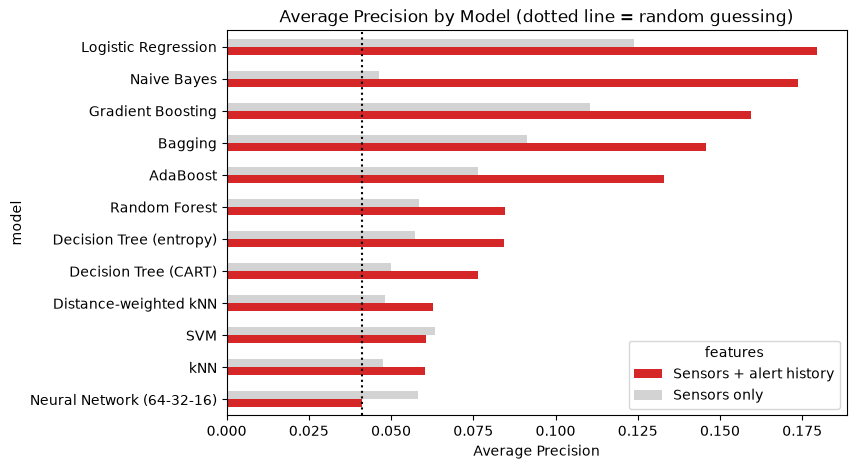

In [27]:
pivot = results.pivot(index='model', columns='features', values='AP').sort_values('Sensors + alert history')
pivot.plot(kind='barh', figsize=(8, 5), color=['tab:red', 'lightgray'])
plt.axvline(y.mean(), color='black', linestyle=':')
plt.title('Average Precision by Model (dotted line = random guessing)')
plt.xlabel('Average Precision')
plt.show()

**Observations**

*Sensors only:* The best models were Gradient Boosting (ROC-AUC 0.76) and Logistic Regression (ROC-AUC 0.72, AP 0.12), compared to 0.50 and 0.04 for random guessing. This means the sensor data does contain some signal for agitation, but it is weak. kNN, distance-weighted kNN, naive Bayes, the decision trees, and the neural network were all close to random (ROC-AUC 0.53 - 0.58). kNN depends on distances between days, but participants have very different normal activity levels, so days that look "close" are really from the same type of participant and not from the same type of day. A single decision tree is also unstable with so few agitation days.

*Adding alert history:* Almost every model improved once the past alerts were included (for example Gradient Boosting ROC-AUC 0.76 to 0.82 and recall in the top 10% from 0.30 to 0.50, Logistic Regression AP 0.12 to 0.18). Agitation seems to happen in bursts, so having agitation recently is the best sign of having it tomorrow. Gradient Boosting was best at ranking (ROC-AUC 0.82), and Logistic Regression had the best average precision (0.18) while also being the easiest to interpret.

*Ensembles vs single models:* Bagging, AdaBoost, and Gradient Boosting did better than a single decision tree (ROC-AUC 0.76 - 0.82 compared to 0.54 - 0.67) because averaging many trees reduces the variance. Random forest did worse than bagging and boosting here, possibly because it picks random subsets of features, and only a few features are actually useful.

*Neural network:* The deep neural network was the worst model (ROC-AUC 0.54 and 0.52, which is no better than random guessing). With only 115 positive days from 27 participants, a network with thousands of weights likely memorizes the training participants instead of learning something that transfers to new participants. Simple models like logistic regression worked better for this amount of data.

*Important baseline:* The rule "count the agitation alerts from the last 7 days" (no machine learning at all) got an AP of 0.23 and caught 53% of agitation days in the top 10%. That is better than every trained model on those two metrics (best AP 0.18, best recall 0.50), although Gradient Boosting still ranks better overall (ROC-AUC 0.82 vs 0.77). So at this data size, machine learning adds only a little over simply noticing who was recently agitated.

*Caution:* This used one cross-validation split and only 27 participants have any agitation (one participant has 22 of the 115 positive days), so small differences between models (for example 0.15 vs 0.16 AP) should not be treated as meaningful. The labels are also generated from sensor thresholds and then confirmed by clinicians, so they are not a perfect record of behavior.

**Conclusion**

* Predicting agitation for participants the model has never seen is hard: the best ROC-AUC was 0.82 and the best AP was 0.18 (random guessing is 0.5 and 0.04).
* Gradient Boosting, Logistic Regression, Bagging and AdaBoost worked best. kNN, naive Bayes, decision trees, SVM and the neural network were close to random on the sensor data.
* Past alerts were the most helpful information, and a simple 7-day alert count was a strong baseline that the models did not clearly beat.
* The deep neural network did not beat simpler models because the dataset is small and participants differ a lot from each other.
* Not included: Bayesian belief networks and rule-based classifiers.